In [3]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph

In [4]:
from os import stat

#State schema

class AgentState(TypedDict):
  message : str


def greeting(state:AgentState) -> AgentState:
  """ A simple node that returns or updates the state with a greetings """
  state["message"] = "Hey " + state["message"] + ". How are you doing? "

  return state

In [5]:
graph = StateGraph(AgentState)

graph.add_node('greeter', greeting) #name & action

graph.set_entry_point('greeter')
graph.set_finish_point('greeter')

app = graph.compile()

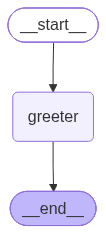

In [6]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [7]:
result = app.invoke({'message': 'Messi'})

In [8]:
result['message']

'Hey Messi. How are you doing? '

#EXERCISE

In [ ]:
class AgentState(TypedDict):
  message : str
  jersey_num : int


def complmt_agent(state : AgentState) -> AgentState:
  " A node that complements the player for being selected to the football team"
  state['message'] = "Hey " + state['message'] + " you did soo good. Welcome to the team, here is your jersey number " + str(state['jersey_num']) + ". Play well!! "

  return state

In [ ]:
graph = StateGraph(AgentState)

graph.add_node('welcome', complmt_agent)

graph.set_entry_point('welcome')
graph.set_finish_point('welcome')

app = graph.compile()

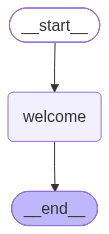

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
result = app.invoke({'message' : 'Messi', 'jersey_num': 10})

result['message']

'Hey Messi you did soo good. Welcome to the team, here is your jersey number 10. Play well!! '